# Breakend enrichment at CFS: exploring the master tables and reproducing the tests

**Data lineage.** Each table is produced by a script from the previous one.

| Level | Table | Script |
|---|---|---|
| Metadata (one row per run) | `data/metadata/cells.tsv` | `scripts/00_metadata/` |
| Alignment (one row per cell) | `data/pilot/align_qc_pilot.tsv` | `scripts/02_align/summarize_align_qc.py` |
| CN per bin (R objects) | `results/pilot_cn/relCN/<donor>_<bin>kb/*.rds` | `copynumber` workflow (QDNAseq) |
| QC per cell and bin | `results/pilot_cn/qc/cn_qc_<bin>kb.tsv` | `scripts/03_cn_qc/cn_qc_metrics.R` |
| Segments | `results/pilot_cn/qc/breakends_<bin>kb_segments.tsv` | `scripts/03_cn_qc/call_breakends.R` |
| Breakends and events | `results/enrichment/pilot/{main,nocuts}/{breakends,events}_<bin>kb.tsv` | `scripts/06_enrichment/build_event_table.py` |
| **Master tables** | `results/enrichment/pilot/master_{cells,breakends,events}.tsv` (+ `master_tables.xlsx`) | `scripts/06_enrichment/build_master_tables.py` |
| Test results | `results/enrichment/pilot/main/test_{a,b,c}*.tsv` | `test_a_permutation.py`, `test_b_regression.py`, `test_c_per_donor.py` |

**Master tables:**
- **`master_cells`:** one row per cell × bin, with metadata, alignment and CN QC, `pass_cuts` and the number of breakends.
- **`master_breakends`:** one row per breakend × cell × bin × set (`main` = cells passing the cuts; `nocuts` = `depth_ok` only). It includes the interval, flank ratios, deviation, stratum, direction, type, RT, the event it belongs to, and one `ov:<set>` (0/1) column per catalogue.
- **`master_events`:** one row per collapsed event, with `ov:<set>` and the exact null probability `p:<set>` used by test A.

In [1]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
RES = f"{ROOT}/results/enrichment/pilot"
sys.path.insert(0, f"{ROOT}/scripts/06_enrichment")
from test_a_permutation import Null, feature_sets, overlaps, stats, rng_for
from genome_annot import PERICEN

pd.set_option("display.max_columns", 60); pd.set_option("display.width", 220)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})
DCOL = {"P18": "#4c72b0", "P20": "#55a868", "P36": "#8172b2", "P07": "#c44e52", "P08": "#dd8452"}
DONORS = ["P18", "P20", "P36", "P07", "P08"]

cells = pd.read_csv(f"{RES}/master_cells.tsv", sep="\t")
brk = pd.read_csv(f"{RES}/master_breakends.tsv", sep="\t", dtype={"chromosome": str})
ev = pd.read_csv(f"{RES}/master_events.tsv", sep="\t", dtype={"chromosome": str})
print("cells", cells.shape, "| breakends", brk.shape, "| events", ev.shape)
print("feature sets:", sorted(c[3:] for c in ev.columns if c.startswith("ov:")))

cells (26263, 30) | breakends (6149, 43) | events (2388, 66)
feature sets: ['A_plus_C:all', 'breast_predicted:all', 'brison2019:all', 'consensusA:all', 'consensusA:core', 'consensusA:reproducible', 'genes_1mb', 'genes_300kb', 'humcfs:all', 'ji2020:HBE', 'ji2020:HeLa', 'ji2020:U2OS', 'ji2020:all', 'letallec2013:MCF10A', 'letallec2013:all', 'letallec2013:epithelial', 'macheret2020:HS68', 'macheret2020:HeLa', 'macheret2020:U2OS', 'macheret2020:all', 'sarni2020:all', 'simpson2021:all', 'union_all:all', 'wilson2015:all']


## 1 · Cell table

Main columns: `reads` (usable reads counted by QDNAseq), `depth_ok`, `noise_excess`, `rt_rho`, `pass_cuts` (`depth_ok` and noise ≤ 1.5 and `rt_rho` ≤ 0.10), `ploidy_best` (best unfiltered absolute fit) and breakend counts under the main definition (E2–E4).

In [2]:
display(cells.head(3))
summary = cells.groupby(["bin_kb", "donor"]).agg(cells=("cell_id", "size"), depth_ok=("depth_ok", "sum"),
                                                  pass_cuts=("pass_cuts", "sum"),
                                                  median_reads=("reads", "median"),
                                                  cells_with_loss=("interstitial_loss", lambda x: int((x > 0).sum())),
                                                  cells_with_gain=("interstitial_gain", lambda x: int((x > 0).sum())))
display(summary)

,cell_id,donor,bin_kb,coassay,instrument,layout,read_length,runs,reads_in,dup_pct,reads,depth_ok,noise_excess,rt_rho,pass_cuts,used_bins,ploidy,nrpbpcc,depth_ok_reads,clonality,ploidy_best,clonality_best,fit_disagree,ploidy_flag,breakpoints,frac_nondiploid,breakends_main,interstitial_loss,interstitial_gain,mapped_pct
0,P07_chip1_co_r0c22,P07,200,1,NextSeq 2000,SINGLE,46,1,365729,42.14,158079,0,1.099,-0.009,0,12017,2.1,5.47,0,0.0046,2.1,0.0046,0,0,0,0.0,0,0,0,98.11
1,P07_chip1_co_r0c23,P07,200,1,NextSeq 2000,SINGLE,46,1,441288,43.59,183803,0,1.102,0.006,0,12017,2.1,6.16,0,0.0039,2.1,0.0039,0,0,0,0.0,0,0,0,97.56
2,P07_chip1_co_r0c25,P07,200,1,NextSeq 2000,SINGLE,46,1,85115,37.73,39675,0,1.073,-0.002,0,12017,2.3,1.20,0,0.0088,2.3,0.0088,0,0,0,0.0,0,0,0,98.06


cells  depth_ok  pass_cuts  median_reads  cells_with_loss  cells_with_gain
bin_kb donor                                                                            
200    P07     1975       116         86      131128.0                6                6
       P08     1229       721        718      466686.0               28              221
       P18     1356       778        778      457046.5                7                7
       P20     2606       454        448      290193.0                8                9
       P36     1568        22         22       80859.5                2                1
500    P07     1975       618        536      131128.0               25               14
       P08     1229      1165       1155      466686.0               22              258
       P18     1356      1276       1275      457046.5                8                9
       P20     2606      1924       1889      290193.0               16               22
       P36     1568       178        177       80859.5               11                1
1000   P07     2036      1376       1235      127223.0               63                9
       P08     1229      1213       1179      466686.0                9              228
       P18     1356      1314       1310      457046.5                8                3
       P20     2606      2160       2013      290193.0               13               21
       P36     1568       583        560       80859.5               25                3

In [3]:
# filter example: cells that pass the cuts at 500 kb and carry an interstitial loss
x = cells[(cells.bin_kb == 500) & (cells.pass_cuts == 1) & (cells.interstitial_loss > 0)]
print(len(x), "cells")
display(x[["cell_id", "donor", "coassay", "instrument", "reads", "noise_excess", "rt_rho", "breakends_main",
           "interstitial_loss", "interstitial_gain"]].sort_values("donor").head(15))

76 cells


,cell_id,donor,coassay,instrument,reads,noise_excess,rt_rho,breakends_main,interstitial_loss,interstitial_gain
9041,P07_chip1_co_r50c5,P07,1,NextSeq 2000,1165142,1.126,-0.019,2,2,0
9206,P07_chip1_co_r8c23,P07,1,NextSeq 2000,296899,1.241,0.022,2,2,0
9216,P07_chip1_co_r8c6,P07,1,NextSeq 2000,2567347,1.189,0.000,2,2,0
9454,P07_chip1_dna_r21c2,P07,0,Illumina HiSeq 4000,289325,1.110,0.008,2,2,0
9484,P07_chip1_dna_r22c38,P07,0,Illumina HiSeq 4000,193477,1.105,0.020,2,2,0
9593,P07_chip1_dna_r28c16,P07,0,Illumina HiSeq 4000,274861,1.065,0.003,2,2,0
9788,P07_chip1_dna_r36c23,P07,0,Illumina HiSeq 4000,221127,1.016,0.033,2,2,0
9860,P07_chip1_dna_r39c36,P07,0,Illumina HiSeq 4000,188989,1.008,0.031,2,1,0
9875,P07_chip1_dna_r3c28,P07,0,Illumina HiSeq 4000,240619,1.028,0.030,2,1,0
10113,P07_chip1_dna_r49c44,P07,0,Illumina HiSeq 4000,180631,0.984,0.065,2,2,0


## 2 · Breakend and event tables

A **breakend** belongs to one cell. An **event** groups the breakends of the same donor, chromosome, direction and type lying within ≤ 2 Mb of each other, so a clone counts once. Tests A and B use events; test C uses breakends.

In [4]:
m = brk[brk.set == "main"]
display(m.head(3))
t = pd.crosstab([m.bin_kb, m.type, m.direction], m.stratum, margins=True)
display(t)
e = ev[ev.set == "main"]
print("events per bin:", e.groupby("bin_kb").size().to_dict())
display(e[e.type == "interstitial"].groupby(["bin_kb", "donor", "direction"]).size().unstack(fill_value=0))

,set,bin_kb,chromosome,pos,lo,hi,left_rel,right_rel,deviation,stratum,direction,terminal,cell_id,donor,type,rt,event_id,rt_quintile,main_def,ov:A_plus_C:all,ov:breast_predicted:all,ov:brison2019:all,ov:consensusA:all,ov:consensusA:core,ov:consensusA:reproducible,ov:humcfs:all,ov:ji2020:all,ov:ji2020:HBE,ov:ji2020:HeLa,ov:ji2020:U2OS,ov:letallec2013:all,ov:letallec2013:MCF10A,ov:macheret2020:all,ov:macheret2020:HS68,ov:macheret2020:HeLa,ov:macheret2020:U2OS,ov:sarni2020:all,ov:simpson2021:all,ov:union_all:all,ov:wilson2015:all,ov:letallec2013:epithelial,ov:genes_300kb,ov:genes_1mb
0,main,200,1,132900000,120200001,145600000,1.0310,1.4893,0.4893,E3,gain,True,P07_chip1_co_r39c33,P07,arm_level,68.115604,1,5,True,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1
1,main,200,1,132900000,120200001,145600000,1.0124,1.9939,0.9939,E4,gain,True,P07_chip1_co_r45c40,P07,arm_level,68.115604,1,5,True,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1
2,main,200,1,235600000,235400001,235800000,1.0083,0.7732,0.2268,E1,loss,False,P07_chip1_co_r16c23,P07,interstitial,70.846306,2,5,False,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


stratum                         E1   E2    E3  E4   All
bin_kb type         direction                          
200    arm_level    gain         1    4    10   5    20
                    loss         0    2    12   0    14
       interstitial gain       166  174   416  26   782
                    loss        22   24    76   0   122
                    mixed        0    1     0   0     1
500    arm_level    gain         4    5    36   8    53
                    loss         2    0    58   0    60
       interstitial gain       200  150   476  13   839
                    loss        18   11   124   0   153
1000   arm_level    gain         3    1    35  11    50
                    loss         1    0    98   0    99
                    mixed        0    0     3   0     3
       interstitial gain       110   54   431   3   598
                    loss        15   12   146   0   173
All                            542  438  1921  66  2967

events per bin: {200: 428, 500: 438, 1000: 259}


direction     gain  loss  mixed
bin_kb donor                   
200    P07       4     8      0
       P08     277    47      1
       P18      14    13      0
       P20      27    19      0
       P36       1     1      0
500    P07      25    33      0
       P08     197    23      0
       P18      23    17      0
       P20      55    25      0
       P36       1     9      0
1000   P07      16    46      0
       P08      84    10      0
       P18      11    13      0
       P20      18    17      0
       P36       6    11      0

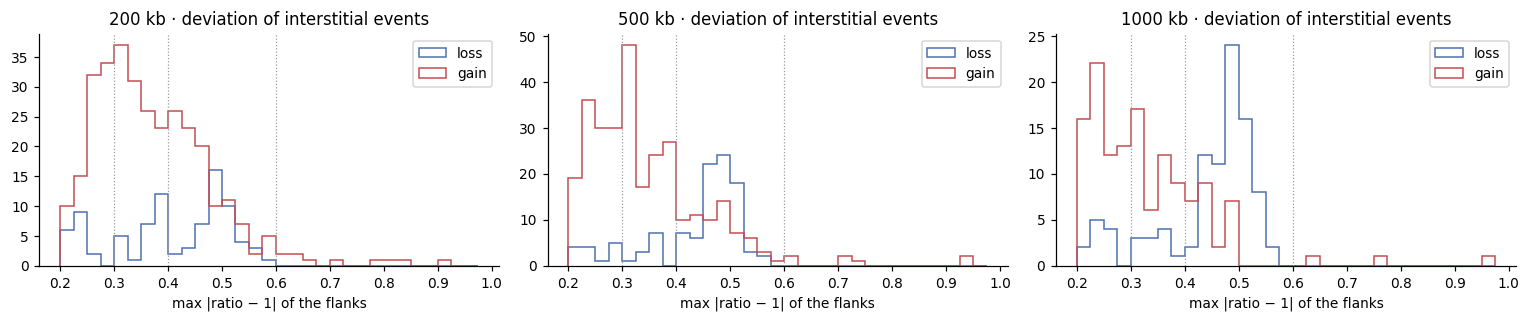

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3))
for ax, b in zip(axes, (200, 500, 1000)):
    x = e[(e.bin_kb == b) & (e.type == "interstitial")]
    for d, col in (("loss", "#4c72b0"), ("gain", "#c44e52")):
        ax.hist(x[x.direction == d].deviation, bins=np.arange(0.2, 1.0, 0.025), histtype="step", color=col, label=d)
    for v in (0.3, 0.4, 0.6):
        ax.axvline(v, color="#999999", ls=":", lw=.8)
    ax.set_title(f"{b} kb · deviation of interstitial events"); ax.set_xlabel("max |ratio − 1| of the flanks"); ax.legend()
plt.tight_layout(); plt.show()

*Method:* dotted lines are the stratum limits (E1 < 0.3 ≤ E2 < 0.4 ≤ E3 < 0.6 ≤ E4). In a diploid cell, one copy more or less gives a deviation of 0.5.

## 3 · Cell viewer (from the segment table)

The profile is drawn from the `call_breakends.R` segments, which exist for every cell. It does not show individual bins; those are exported only for the example cells (notebook 01). Bands are the cell's breakends: blue = loss, red = gain, in that bin.

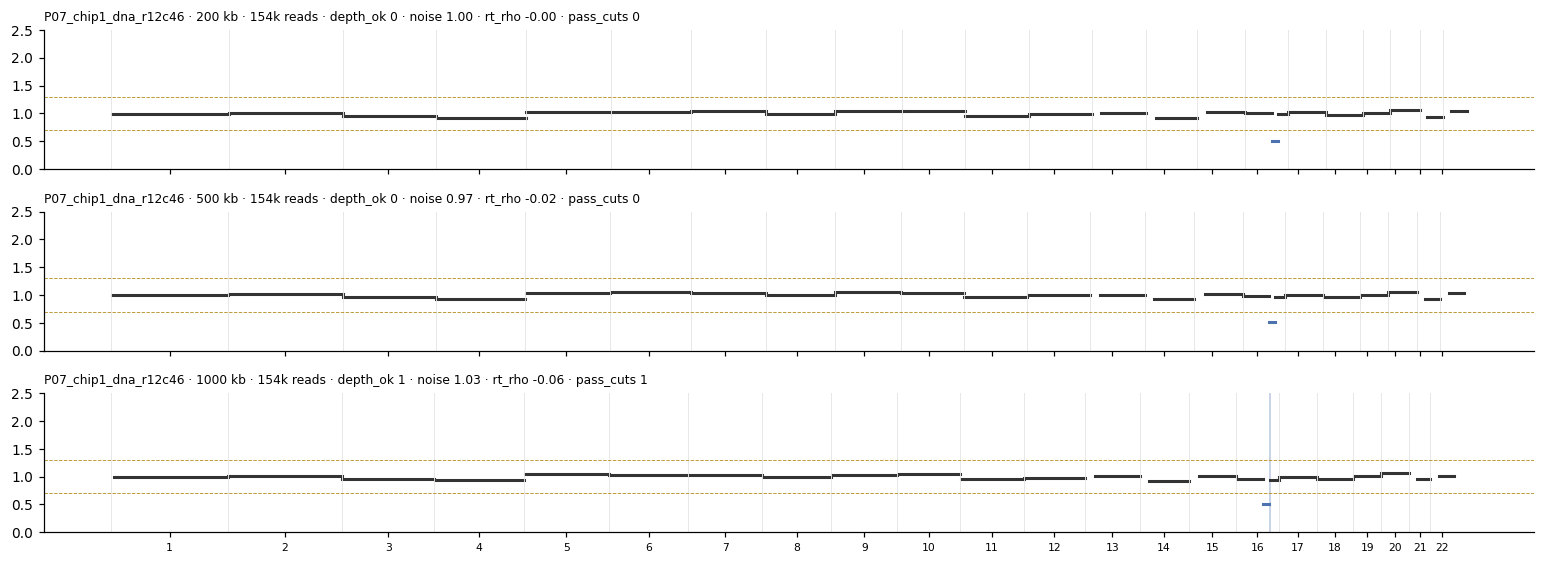

In [6]:
seg = {b: pd.read_csv(f"{ROOT}/results/pilot_cn/qc/breakends_{b}kb_segments.tsv", sep="\t", dtype={"chromosome": str})
       for b in (200, 500, 1000)}
CHR = [str(i) for i in range(1, 23)]

def plot_cell(cell):
    fig, axes = plt.subplots(3, 1, figsize=(14, 5.2), sharex=True)
    for ax, b in zip(axes, (200, 500, 1000)):
        s = seg[b][seg[b].cell_id == cell].copy()
        if s.empty:
            ax.text(.5, .5, "no data", transform=ax.transAxes); continue
        off = {}; acc = 0
        for c in CHR:
            off[c] = acc; acc += s[s.chromosome == c].end.max() if (s.chromosome == c).any() else 0
        for r in s.itertuples():
            x0, x1 = off[r.chromosome] + r.start, off[r.chromosome] + r.end
            col = "#c44e52" if r.rel > 1.3 else "#4c72b0" if r.rel < 0.7 else "#333333"
            ax.plot([x0 / 1e6, x1 / 1e6], [min(r.rel, 3)] * 2, color=col, lw=2)
        for c in CHR:
            ax.axvline(off[c] / 1e6, color="#e5e5e5", lw=.6)
        bb = brk[(brk.set == "nocuts") & (brk.bin_kb == b) & (brk.cell_id == cell)]
        for r in bb.itertuples():
            ax.axvspan((off[r.chromosome] + r.lo) / 1e6, (off[r.chromosome] + r.hi) / 1e6,
                       color="#4c72b0" if r.direction == "loss" else "#c44e52", alpha=.3, lw=0)
        q = cells[(cells.cell_id == cell) & (cells.bin_kb == b)].iloc[0]
        ax.axhline(1.3, color="#b8962e", ls="--", lw=.6); ax.axhline(.7, color="#b8962e", ls="--", lw=.6)
        ax.set_ylim(0, 2.5)
        ax.set_title(f"{cell} · {b} kb · {int(q.reads/1e3)}k reads · depth_ok {q.depth_ok} · noise {q.noise_excess:.2f} · "
                     f"rt_rho {q.rt_rho:.2f} · pass_cuts {q.pass_cuts}", loc="left", fontsize=8)
    mids = [(off[c] + (off[CHR[i + 1]] if i < 21 else acc)) / 2e6 for i, c in enumerate(CHR)]
    axes[-1].set_xticks(mids, CHR, fontsize=7)
    plt.tight_layout(); plt.show()

CELL = "P07_chip1_dna_r12c46"   # change to any cell_id of master_cells
plot_cell(CELL)

## 4 · Reproduce test A

For a subset of events, test A compares how many overlap a site set (**O**) with how many would by chance (**E = Σ pᵢ**). Here **pᵢ** is the fraction of the event's candidate placements (same chromosome, same RT quintile, same width, outside pericentromeric blocks) that overlap the set. `master_events` already carries `ov:` (oᵢ) and `p:` (pᵢ).

Change `SET`, `BIN`, `DIRECTION` and `STRATUM` to reproduce any row of `test_a.tsv`.

In [7]:
SET, BIN, DIRECTION, STRATUM = "macheret2020:HS68", 500, "loss", "main"

x = ev[(ev.set == "main") & (ev.bin_kb == BIN) & (ev.type == "interstitial")]
if DIRECTION != "all":
    x = x[x.direction == DIRECTION]
x = x[x.stratum.isin(["E2", "E3", "E4"])] if STRATUM == "main" else x[x.stratum == STRATUM]
x = x[x[f"p:{SET}"].notna()]
O, E = int(x[f"ov:{SET}"].sum()), x[f"p:{SET}"].sum()
print(f"{len(x)} events · O = {O} · E = {E:.2f} · fold = {O / E:.2f}")

r = stats(x[f"ov:{SET}"].values.astype(bool), x[f"p:{SET}"].values, x.donor.values, rng_for(1, BIN, SET, DIRECTION, STRATUM))
print("with the same function as the script:", r)

ta = pd.read_csv(f"{RES}/main/test_a.tsv", sep="\t")
display(ta[(ta.feature_set == SET) & (ta.bin_kb == BIN) & (ta.direction == DIRECTION) & (ta.stratum == STRATUM)])

93 events · O = 10 · E = 2.48 · fold = 4.03
with the same function as the script: {'n_events': 93, 'observed': 10, 'expected': 2.483, 'fold': 4.027, 'fold_lo': np.float64(2.112), 'fold_hi': np.float64(6.28), 'fold_lo_donor': np.float64(2.456), 'fold_hi_donor': np.float64(5.305), 'p_enrich': 0.00011541970073573715, 'p_deplete': 0.9999801870021097}


,bin_kb,feature_set,direction,stratum,n_events,observed,expected,fold,fold_lo,fold_hi,fold_lo_donor,fold_hi_donor,p_enrich,p_deplete,p_perm,n_perm,q_family,q_global,q_perm_global
574,500,macheret2020:HS68,loss,main,93,10.0,2.483,4.027,2.112,6.28,2.456,5.304,0.000115,0.99998,0.0004,5000.0,0.004849,0.022859,0.079184


*Note:* O, E, the fold and the exact p-value (Poisson-binomial, no simulation) match `test_a.tsv`; the bootstrap CIs use the same per-test seed (`rng_for`) and match too, up to the rounding of pᵢ in `master_events`. The permutation p (`p_perm`, 5,000 site shuffles) is only in `test_a.tsv`: it is too slow to recompute here.

### 4.1 The null, step by step

To understand one pᵢ: the candidate placements of an event and which of them overlap the set.

event chr18:8.00-9.00 Mb · donor P07 · RT quintile 3
26 candidate placements · 2 overlap macheret2020:HS68 · p = 0.0769 (table: 0.0769)


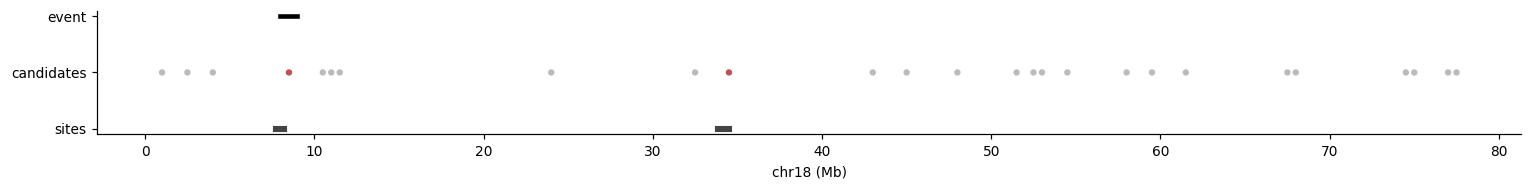

In [8]:
fs = feature_sets(f"{ROOT}/data/features/cfs/cfs_catalogs_hg19.tsv", f"{ROOT}/data/features/genes")
bins = pd.read_csv(f"{RES}/main/usable_bins_rt_{BIN}kb.tsv", sep="\t", dtype={"chromosome": str})
null = Null(bins)
hit = x[x[f"ov:{SET}"] == 1].iloc[0]
a, b = null.candidates(hit.chromosome, int(hit.rt_quintile), int(hit.hi - hit.lo))
ov = overlaps(fs[SET], hit.chromosome, a, b)
print(f"event chr{hit.chromosome}:{hit.lo/1e6:.2f}-{hit.hi/1e6:.2f} Mb · donor {hit.donor} · RT quintile {int(hit.rt_quintile)}")
print(f"{len(a)} candidate placements · {ov.sum()} overlap {SET} · p = {ov.mean():.4f} (table: {hit[f'p:{SET}']:.4f})")
fig, ax = plt.subplots(figsize=(14, 1.8))
ax.scatter((a + b) / 2e6, np.zeros(len(a)), c=np.where(ov, "#c44e52", "#bbbbbb"), s=10)
ax.plot([hit.lo / 1e6, hit.hi / 1e6], [0.5, 0.5], color="k", lw=3)
S, Ee = fs[SET].get(hit.chromosome, (np.array([]), np.array([])))
for s0, e0 in zip(S, Ee):
    ax.plot([s0 / 1e6, e0 / 1e6], [-0.5, -0.5], color="#444444", lw=4)
ax.set_yticks([-0.5, 0, 0.5], ["sites", "candidates", "event"]); ax.set_xlabel(f"chr{hit.chromosome} (Mb)")
plt.tight_layout(); plt.show()

### 4.2 Which events overlap

The events of the subset that overlap the set, with their pᵢ and the number of cells carrying them.

In [9]:
display(x[x[f"ov:{SET}"] == 1][["donor", "chromosome", "pos", "lo", "hi", "direction", "stratum", "deviation", "n_cells",
                                 "rt_quintile", f"p:{SET}"]].sort_values(["donor", "chromosome"]))

,donor,chromosome,pos,lo,hi,direction,stratum,deviation,n_cells,rt_quintile,p:macheret2020:HS68
461,P07,18,8500000,8000001,9000000,loss,E3,0.4153,1,3.0,0.07692
483,P07,7,68250000,67000001,69500000,loss,E3,0.5035,2,2.0,0.15116
484,P07,7,77500000,77000001,78000000,loss,E3,0.5047,1,4.0,0.02222
487,P07,7,134250000,133500001,135000000,loss,E3,0.5052,1,4.0,0.04255
562,P08,13,107500000,107000001,108000000,loss,E3,0.4077,1,1.0,0.05172
628,P08,2,143000000,142500001,143500000,loss,E3,0.4526,1,2.0,0.08333
758,P18,7,111750000,111000001,112500000,loss,E3,0.4735,1,3.0,0.05405
789,P20,13,109000000,108500001,109500000,loss,E2,0.3278,1,2.0,0.08571
856,P36,12,100500000,100000001,101000000,loss,E3,0.5164,1,3.0,0.06383
857,P36,14,67000000,66500001,67500000,loss,E3,0.4970,1,3.0,0.14286


## 5 · Reproduce test B (one model)

Regression per donor × 1 Mb window, with the same fitting function as the script.

In [10]:
from test_b_regression import windows, assign_windows, feature_effect, MODELS
w = windows(f"{RES}/main", f"{ROOT}/external/sWGS_relativeCN/bin.annotations/bins_with_replicationTime_50kb.tsv",
            f"{ROOT}/data/features/genes")
w["feature"] = [int(overlaps(fs[SET], c, s, e2)[0]) for c, s, e2 in zip(w.chromosome, w.start, w.end)]
evb = pd.read_csv(f"{RES}/main/events_{BIN}kb.tsv", sep="\t", dtype={"chromosome": str})
evb = evb[(evb.type == "interstitial") & evb.main_def & ((evb.direction == DIRECTION) if DIRECTION != "all" else True)]
evb = evb.assign(widx=assign_windows(evb, w))  # window with the largest overlap; -1 = no eligible window
print(f"{(evb.widx < 0).sum()} of {len(evb)} events overlap no eligible window")
cnt = evb[evb.widx >= 0].groupby(["donor", "widx"]).size()
donors = sorted(pd.read_csv(f"{RES}/main/events_{BIN}kb.tsv", sep="\t").query("type == 'interstitial'").donor.unique())
df = pd.concat([w.assign(donor=d, widx=w.index) for d in donors], ignore_index=True)
df["events"] = cnt.reindex(list(zip(df.donor, df.widx))).fillna(0).values
for label, f in MODELS:
    r = feature_effect(df, f)
    print(f"{label}: IRR = {r['irr']:.2f} [{r['irr_lo']:.2f}-{r['irr_hi']:.2f}], p = {r['p']:.3g} ({r['family']}, SE {r['se_source']})")
tb = pd.read_csv(f"{RES}/main/test_b.tsv", sep="\t")
display(tb[(tb.feature_set == SET) & (tb.bin_kb == BIN) & (tb.direction == DIRECTION) & (tb.stratum == "main")])

3 of 93 events overlap no eligible window
crude: IRR = 3.69 [1.83-7.46], p = 0.000269 (poisson, SE cluster)


adjusted: IRR = 3.40 [1.46-7.90], p = 0.00449 (poisson, SE cluster)


adjusted_genes300: IRR = 3.99 [1.70-9.37], p = 0.00147 (poisson, SE cluster)


,bin_kb,direction,stratum,feature_set,model,n_events_input,n_events_excluded,n_events,n_events_feature,n_windows,n_windows_feature,family,alpha,irr,irr_lo,irr_hi,p,se_source,irr_rt,irr_genes300,note,q_family,q_global
369,500,loss,main,macheret2020:HS68,crude,93,3,90,9,1917,56,poisson,-1.01455,3.69246,1.82872,7.45564,0.00027,cluster,NaN,NaN,NaN,0.00360,0.04596
370,500,loss,main,macheret2020:HS68,adjusted,93,3,90,9,1917,56,poisson,-1.07656,3.39690,1.46124,7.89669,0.00449,cluster,1.40048,NaN,NaN,0.02232,0.38422
371,500,loss,main,macheret2020:HS68,adjusted_genes300,93,3,90,9,1917,56,poisson,-1.04654,3.99345,1.70119,9.37439,0.00147,cluster,1.38303,0.5845,NaN,0.00882,0.12575


## 6 · Reproduce test C (per donor)

At breakend level (clones not collapsed). `master_breakends` has `ov:`; each breakend's pᵢ is computed here with the same null.

In [11]:
bb = brk[(brk.set == "main") & (brk.bin_kb == BIN) & (brk.type == "interstitial") & brk.stratum.isin(["E2", "E3", "E4"])]
if DIRECTION != "all":
    bb = bb[bb.direction == DIRECTION]
cache, p = {}, []
for r in bb.itertuples():
    k = (r.chromosome, int(r.rt_quintile), int(r.hi - r.lo))
    if k not in cache:
        a2, b2 = null.candidates(*k[:2], k[2])
        cache[k] = overlaps(fs[SET], r.chromosome, a2, b2).mean() if len(a2) else np.nan
    p.append(cache[k])
bb = bb.assign(p=p)
per = bb.groupby("donor").agg(cells=("cell_id", "nunique"), breakends=("p", "size"), O=(f"ov:{SET}", "sum"), E=("p", "sum"))
per["O/E"] = (per.O / per.E).round(2)
display(per)
print(f"pooled: O = {per.O.sum()}, E = {per.E.sum():.2f}, O/E = {per.O.sum() / per.E.sum():.2f}")
tc = pd.read_csv(f"{RES}/main/test_c.tsv", sep="\t")
display(tc[(tc.feature_set == SET) & (tc.bin_kb == BIN) & (tc.direction == DIRECTION)])

,cells,breakends,O,E,O/E
donor,,,,,
P07,20,36,5,0.882084,5.67
P08,21,42,2,0.739982,2.70
P18,8,15,1,0.251830,3.97
P20,16,27,1,1.054200,0.95
P36,11,15,2,0.443971,4.50


pooled: O = 11, E = 3.37, O/E = 3.26


,bin_kb,feature_set,direction,donor,breakends,cells,observed,expected,ratio,ratio_lo,ratio_hi,ci,het_X2,het_p
414,500,macheret2020:HS68,loss,pooled,135,76,11,3.37,3.262,1.816,4.622,bootstrap,1.73,NaN
415,500,macheret2020:HS68,loss,P07,36,20,5,0.88,5.668,2.870,9.141,bootstrap,NaN,NaN
416,500,macheret2020:HS68,loss,P08,42,21,2,0.74,2.703,0.000,6.312,bootstrap,NaN,NaN
417,500,macheret2020:HS68,loss,P18,15,8,1,0.25,3.971,0.000,8.556,bootstrap,NaN,NaN
418,500,macheret2020:HS68,loss,P20,27,16,1,1.05,0.949,0.000,3.189,bootstrap,NaN,NaN
419,500,macheret2020:HS68,loss,P36,15,11,2,0.44,4.505,0.000,7.575,bootstrap,NaN,NaN


## 7 · Region viewer

Breakends of every cell (main set) around a locus, with the catalogue sites and replication timing. Change `REGION`.

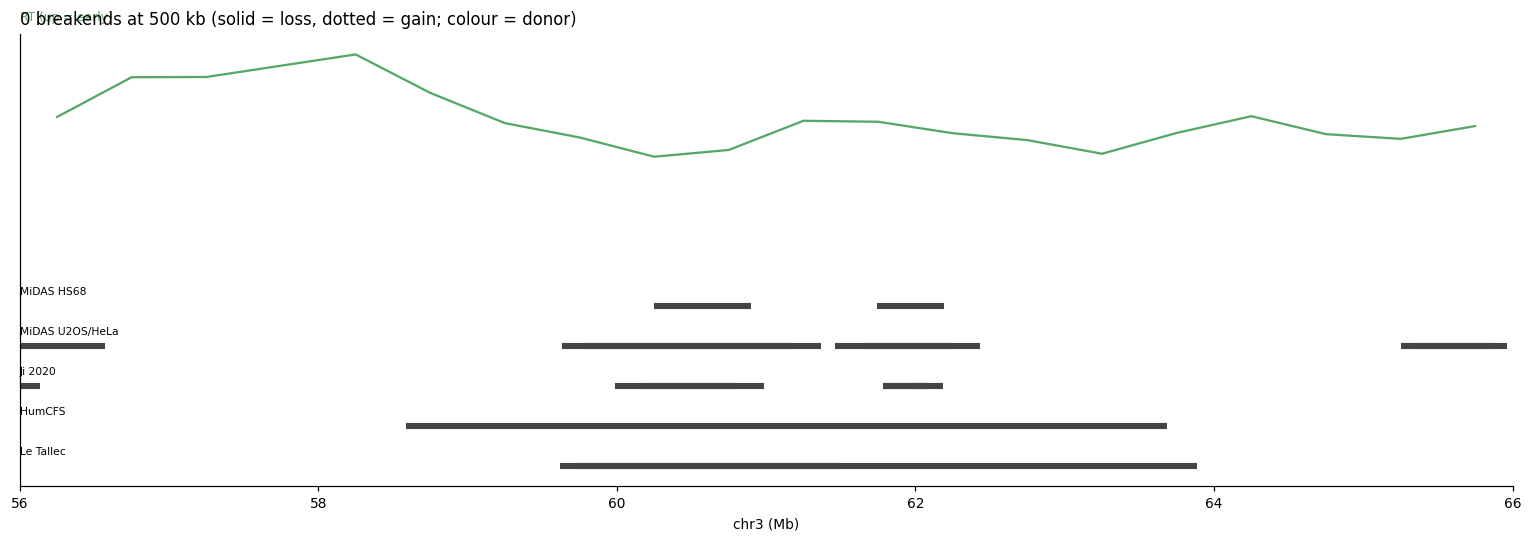

,cell_id,donor,lo,hi,direction,stratum,deviation,event_id


In [12]:
REGION = ("3", 56e6, 66e6)   # FHIT; e.g. ("2", 138e6, 148e6) LRP1B, ("16", 76e6, 82e6) WWOX
cfs = pd.read_csv(f"{ROOT}/data/features/cfs/cfs_catalogs_hg19.tsv", sep="\t"); cfs["chromosome"] = cfs.chrom.str.replace("chr", "")
c, s0, e0 = REGION
fig, ax = plt.subplots(figsize=(14, 5))
rt = bins[(bins.chromosome == c) & (bins.start >= s0) & (bins.end <= e0)]
ax.plot((rt.start + rt.end) / 2e6, 8 + rt.rt / 40, color="#55a868"); ax.text(s0 / 1e6, 10.2, "RT (up = early)", color="#55a868", fontsize=8)
tracks = [("MiDAS HS68", cfs[(cfs.catalog == "macheret2020") & (cfs.cell_type == "HS68")]),
          ("MiDAS U2OS/HeLa", cfs[(cfs.catalog == "macheret2020") & (cfs.cell_type != "HS68")]),
          ("Ji 2020", cfs[cfs.catalog == "ji2020"]), ("HumCFS", cfs[cfs.catalog == "humcfs"]), ("Le Tallec", cfs[cfs.catalog == "letallec2013"])]
for k, (lab, sub) in enumerate(tracks):
    y = 7 - k * .45
    for r in sub[(sub.chromosome == c) & (sub.end >= s0) & (sub.start <= e0)].itertuples():
        ax.plot([max(r.start, s0) / 1e6, min(r.end, e0) / 1e6], [y, y], lw=4, color="#444444", solid_capstyle="butt")
    ax.text(s0 / 1e6, y + .12, lab, fontsize=7)
bb2 = brk[(brk.set == "main") & (brk.bin_kb == BIN) & (brk.chromosome == c) & (brk.hi >= s0) & (brk.lo <= e0)].sort_values("pos")
for i, r in enumerate(bb2.itertuples()):
    ax.plot([r.lo / 1e6, r.hi / 1e6], [4.4 - i * .1] * 2, color=DCOL[r.donor], lw=2, ls="-" if r.direction == "loss" else ":")
ax.set_xlim(s0 / 1e6, e0 / 1e6); ax.set_yticks([]); ax.set_xlabel(f"chr{c} (Mb)")
ax.set_title(f"{len(bb2)} breakends at {BIN} kb (solid = loss, dotted = gain; colour = donor)", loc="left")
plt.tight_layout(); plt.show()
display(bb2[["cell_id", "donor", "lo", "hi", "direction", "stratum", "deviation", "event_id"]])

## 8 · Full result tables

`test_a.tsv` has every combination of set × bin × direction × stratum; the results document (`docs/enrichment/enrichment_pilot.html`) shows a selection. Filter example:

In [13]:
display(ta[(ta.stratum == "main") & (ta.direction == "loss")].sort_values("p_enrich").head(15))

,bin_kb,feature_set,direction,stratum,n_events,observed,expected,fold,fold_lo,fold_hi,fold_lo_donor,fold_hi_donor,p_enrich,p_deplete,p_perm,n_perm,q_family,q_global,q_perm_global
574,500,macheret2020:HS68,loss,main,93,10.0,2.483,4.027,2.112,6.280,2.456,5.304,0.000115,0.999980,0.000400,5000.0,0.004849,0.022859,0.079184
559,500,macheret2020:all,loss,main,93,33.0,22.221,1.485,1.141,1.817,1.170,1.769,0.004419,0.997910,0.007598,5000.0,0.092800,0.291656,0.459268
589,500,macheret2020:HeLa,loss,main,93,22.0,13.105,1.679,1.127,2.258,1.104,2.250,0.006799,0.996939,0.011598,5000.0,0.142772,0.336535,0.459268
499,500,ji2020:HeLa,loss,main,93,10.0,4.306,2.322,1.095,3.680,1.300,3.064,0.008844,0.997167,0.009998,5000.0,0.123810,0.350207,0.459268
469,500,ji2020:all,loss,main,93,22.0,14.098,1.561,1.070,2.080,1.175,1.890,0.014436,0.993120,0.017197,5000.0,0.205206,0.476374,0.543491
514,500,ji2020:U2OS,loss,main,93,20.0,13.426,1.490,0.958,2.004,1.210,1.752,0.033143,0.983039,0.032593,5000.0,0.574715,0.640406,0.543491
604,500,macheret2020:U2OS,loss,main,93,24.0,17.161,1.399,1.008,1.839,1.127,1.590,0.035578,0.981096,0.034993,5000.0,0.648742,0.640406,0.543491
889,1000,letallec2013:all,loss,main,86,20.0,14.039,1.425,0.980,1.911,1.017,2.355,0.040752,0.979658,0.067786,5000.0,0.570531,0.671961,0.543491
1039,1000,letallec2013:epithelial,loss,main,86,10.0,5.987,1.670,0.889,2.517,1.371,2.162,0.058910,0.975444,0.051390,5000.0,0.494843,0.730273,0.543491
349,200,genes_1mb,loss,main,71,7.0,3.659,1.913,0.691,3.216,0.703,2.575,0.063460,0.976887,0.065387,5000.0,0.458097,NaN,NaN
